# Libaries and Preamble

In [6]:
import pandas as pd
import numpy 
from functions import read_squid_file
import matplotlib.pyplot as plt
import os

In [7]:
#=======================================================================
# matplotlib rc — academic / journal style
#=======================================================================
plt.rcParams.update({
    "font.family":       "serif",
    "font.size":         10,
    "axes.labelsize":    10,
    "axes.titlesize":    10,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "lines.linewidth":   1.0,
    "axes.linewidth":    0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
    "xtick.major.size":  4.0,
    "ytick.major.size":  4.0,
    "xtick.minor.size":  2.0,
    "ytick.minor.size":  2.0,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.top":         True,
    "ytick.right":       True,
    "axes.grid":         True,
    "grid.color":        "#CCCCCC",
    "grid.linewidth":    0.4,
    "grid.linestyle":    "--",
    "grid.alpha":        0.6,
    "axes.axisbelow":    True,
    "figure.facecolor":  "white",
    "axes.facecolor":    "white",
    "savefig.dpi":       600,
    "savefig.bbox":      "tight",
    "savefig.facecolor": "white",
    "figure.dpi":        150,
    "legend.framealpha": 0.9,
    "legend.edgecolor":  "#AAAAAA",
    "legend.frameon":    True,
})

In [8]:
pb = read_squid_file(
    "/home/thomp/high-temperature-superconductivity/data/2026/10/2026-10-14 Pb MvsT FW Various Field_00001.dat",
)
pb.head()

,Time Stamp (sec),Temperature (K),Magnetic Field (Oe),Moment (emu),M. Std. Err. (emu),Transport Action,Center Position (mm),AC Susceptibility (emu/Oe),AC Suscept. Std Err. (emu/Oe),AC X' (emu/Oe),...,DC Free Fit,DC Calculated Center (mm),DC Calculated Center Err (mm),DC Scan Length (mm),DC Scan Time (s),DC Number of Points,DC Squid Drift,DC Min V (V),DC Max V (V),DC Scans per Measure
0,4.001173e+09,2.001248,149.626175,NaN,NaN,6,31.809032,NaN,NaN,NaN,...,0.992808,31.833864,0.000000e+00,40,1,200,0.002029,-4.738845,4.800665,1
1,4.001173e+09,2.005023,149.626175,NaN,NaN,6,31.809032,NaN,NaN,NaN,...,0.992890,31.833115,1.458402e-37,40,1,200,0.001862,-0.243031,0.745090,1
2,4.001173e+09,2.008357,149.626175,NaN,NaN,6,31.809032,NaN,NaN,NaN,...,0.992801,31.833044,1.477760e-37,40,1,200,0.002042,-0.243009,0.745059,1
3,4.001173e+09,2.018766,149.626175,NaN,NaN,6,31.809032,NaN,NaN,NaN,...,0.992818,31.833153,2.378192e-18,40,1,200,0.002021,-0.242978,0.745098,1
4,4.001173e+09,2.027640,149.626175,NaN,NaN,6,31.809032,NaN,NaN,NaN,...,0.992859,31.833277,2.382340e-18,40,1,200,0.001930,-0.242947,0.745093,1


Text(0.5, 0, 'Temperature (K)')

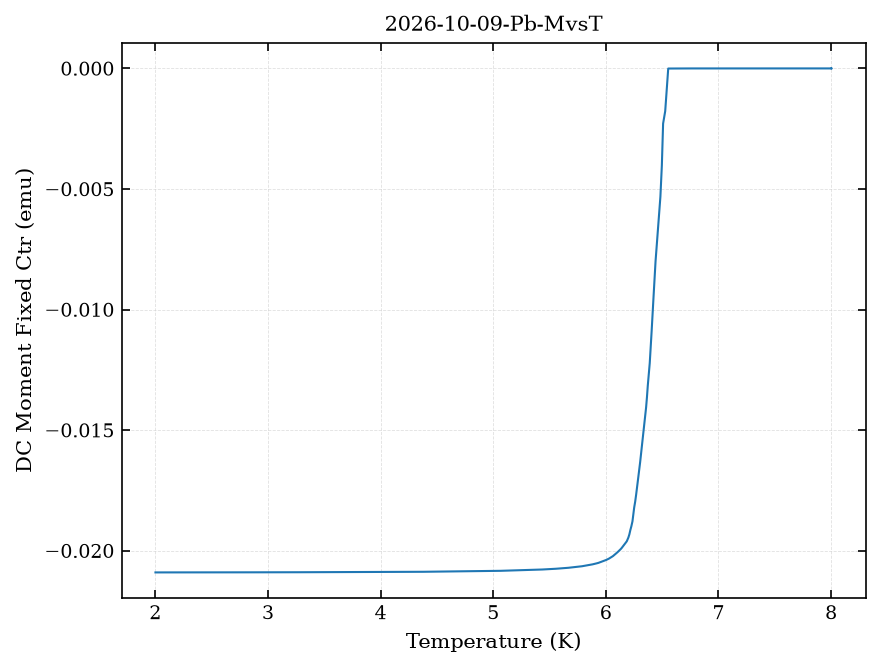

In [9]:
plt.plot(pb["Temperature (K)"],pb["DC Moment Fixed Ctr (emu)"])
plt.title("2026-10-09-Pb-MvsT")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.xlabel("Temperature (K)")

### Current Plan for Data Analysis 
- we need a method for looping throught a set number of files
- easiest way is to make a folder for the data 
- and then loop throught the folder and get all the raw data 


In [29]:
# Source - https://stackoverflow.com/a/10378012
# Posted by anselm, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-15, License - CC BY-SA 4.0
# edited by ben thomposn

from pathlib import Path
runs = {}
pathlist = Path(
    "data/2026/10/26-10-15 Pb Analysis Folder"
).glob("**/*.dat")
for path in sorted(pathlist):
    run_number = path.stem[-5:]
    runs[run_number] = read_squid_file(str(path))
for run_number, data in runs.items():
    print(f"Run {run_number}")

Run 00001
Run 00002
Run 00003
Run 00004
Run 00005


In [34]:
for run_number, dataframe in runs.items():
    print(f"Run {run_number}")
    print(dataframe.head())
    print("="*80)

Run 00001
   Time Stamp (sec)  Temperature (K)  Magnetic Field (Oe)  Moment (emu)  \
0      4.001173e+09         2.001248           149.626175           NaN   
1      4.001173e+09         2.005023           149.626175           NaN   
2      4.001173e+09         2.008357           149.626175           NaN   
3      4.001173e+09         2.018766           149.626175           NaN   
4      4.001173e+09         2.027640           149.626175           NaN   

   M. Std. Err. (emu)  Transport Action  Center Position (mm)  \
0                 NaN                 6             31.809032   
1                 NaN                 6             31.809032   
2                 NaN                 6             31.809032   
3                 NaN                 6             31.809032   
4                 NaN                 6             31.809032   

   AC Susceptibility (emu/Oe)  AC Suscept. Std Err. (emu/Oe)  AC X' (emu/Oe)  \
0                         NaN                            NaN        

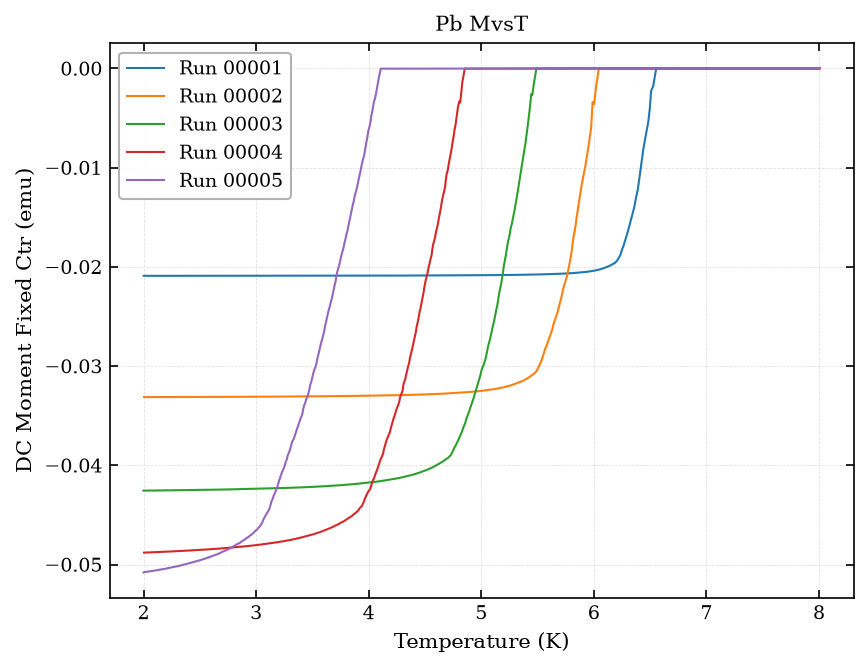

In [37]:

for run_number, dataframe in runs.items():
    plt.plot(
        dataframe["Temperature (K)"],
        dataframe["DC Moment Fixed Ctr (emu)"],
        label=f"Run {run_number}",
    )

plt.title("Pb MvsT")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()
plt.show()